# 03 · ABC, XYZ y parámetros de riesgo

**Objetivo:** clasificar los componentes con los análisis ABC y XYZ, para saber a cuáles se les aplican las políticas de inventario (consigna, sección 2). Después calcula, para los componentes clase A, los parámetros de riesgo que usan las políticas.

**Entrada:** `outputs/serie_mensual.csv` (del 01), `outputs/demanda_anual.csv` (del 02) y `data/sales_data_sample_raw.csv`, para el precio de los autos. Hay que correr el 01 y el 02 antes que este.
**Salida:** `outputs/componentes.csv`, `outputs/abc_componentes.png` y `outputs/parametros.csv`, que usa el notebook 04.

Antes de usar cualquier número en el informe: *Restart* y *Run All*.

**Recorrido:**

1. Cómo se arma un ABC (sección 2).
2. ABC de los componentes (sección 3).
3. XYZ de los componentes (sección 4).
4. Resultado: qué componentes pasan a los modelos de inventario (sección 5).
5. Parámetros de riesgo de los componentes clase A (sección 6).

**Cómo leer las referencias:** en el apunte *Introducción a los Modelos de Inventarios*, el número es el del pie de la diapositiva (por ejemplo, 44/73). Las clases de 2025 se citan por fecha. Cada decisión aclara si tiene **respaldo de la cátedra**, si es **criterio propio** o si viene de una **fuente externa**.

## 1. Carga de datos

Se cargan dos cosas:

- **La demanda anual del 02**, para el ABC.
- **La serie mensual del 01**, para el XYZ.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CARPETA_SALIDA = "outputs"

serie = pd.read_csv(os.path.join(CARPETA_SALIDA, "serie_mensual.csv"), index_col="mes")
demanda = pd.read_csv(os.path.join(CARPETA_SALIDA, "demanda_anual.csv"), index_col="parametro")["valor"]

print("Meses de la serie:", len(serie))
print("Demanda anual pronosticada: Clásicos", demanda["demanda_anual_clasicos"],
      "| Vintage", demanda["demanda_anual_vintage"],
      "| Total", demanda["demanda_anual_total"])

Meses de la serie: 29
Demanda anual pronosticada: Clásicos 20204.5 | Vintage 12430.0 | Total 32634.5


## 2. Cómo se arma un ABC

Se ordenan los ítems de mayor a menor valor y se va acumulando el porcentaje del valor total:

- **A:** los ítems que hacen falta para juntar el 80% del valor.
- **B:** los que siguen, hasta juntar el 95%.
- **C:** el resto.

En la práctica, un ítem es A si, antes de sumarlo, el acumulado todavía no llegaba al 80%; y es B si no llegaba al 95%.

**Respaldo de la cátedra:** los cortes de 80% y 95% son la regla de Pareto, que presenta el libro *Sistemas de optimización de stocks*, de Miguel Miranda (bibliografía de la cátedra). La sección 3 muestra que con un corte de 75% el resultado no cambia.

La función `clasificar_abc` hace exactamente eso. Se usa dos veces: con el corte de 80%, y con 75% como chequeo.

In [2]:
def clasificar_abc(tabla, columna_valor, corte_a=80, corte_b=95):
    tabla = tabla.sort_values(columna_valor, ascending=False).copy()
    tabla["% del valor"] = tabla[columna_valor] / tabla[columna_valor].sum() * 100
    tabla["% acumulado"] = tabla["% del valor"].cumsum()
    acumulado_antes = tabla["% acumulado"] - tabla["% del valor"]

    clases = []
    for antes in acumulado_antes:
        if antes < corte_a:
            clases.append("A")
        elif antes < corte_b:
            clases.append("B")
        else:
            clases.append("C")
    tabla["clase ABC"] = clases
    return tabla

## 3. ABC de los componentes

La tabla de componentes es la de la consigna ("Contexto del Caso"). En la columna `auto`, "Ambos" quiere decir que el componente se usa en las dos líneas.

In [3]:
filas = [
    ["Motor de Alto Rendimiento V8",        "Clásico", 9000,  1, 0.8,  6],
    ["Motor de Cilindros en Línea Raro",    "Vintage", 12000, 1, 0.9,  12],
    ["Carrocería Artesanal de Época",       "Vintage", 15000, 1, 4.0,  10],
    ["Carrocería Estándar (Fibra)",         "Clásico", 6500,  1, 3.5,  4],
    ["Transmisión de 5 Velocidades",        "Ambos",   3500,  1, 0.4,  4],
    ["Sistema de Inyección Electrónica",    "Clásico", 1200,  1, 0.1,  3],
    ["Set de Carburadores Dobles",          "Vintage", 900,   1, 0.1,  5],
    ["Tapicería de Cuero Premium",          "Ambos",   4000,  1, 0.5,  8],
    ["Juego de Llantas Vintage Espec.",     "Vintage", 2500,  4, 0.15, 5],
    ["Llantas Regulares Cromados",          "Clásico", 400,   4, 0.1,  2],
    ["Cubiertas de Alta Gama (Neumáticos)", "Ambos",   250,   4, 0.1,  2],
]
componentes = pd.DataFrame(filas, columns=["componente", "auto", "costo unitario", "uso por auto",
                                           "volumen m3", "lead time semanas"])
componentes

,componente,auto,costo unitario,uso por auto,volumen m3,lead time semanas
0,Motor de Alto Rendimiento V8,Clásico,9000,1,0.80,6
1,Motor de Cilindros en Línea Raro,Vintage,12000,1,0.90,12
2,Carrocería Artesanal de Época,Vintage,15000,1,4.00,10
3,Carrocería Estándar (Fibra),Clásico,6500,1,3.50,4
4,Transmisión de 5 Velocidades,Ambos,3500,1,0.40,4
5,Sistema de Inyección Electrónica,Clásico,1200,1,0.10,3
6,Set de Carburadores Dobles,Vintage,900,1,0.10,5
7,Tapicería de Cuero Premium,Ambos,4000,1,0.50,8
8,Juego de Llantas Vintage Espec.,Vintage,2500,4,0.15,5
9,Llantas Regulares Cromados,Clásico,400,4,0.10,2


Para cada componente:

- **Demanda anual** = demanda anual de autos de la línea que lo usa × uso por auto. Clásico usa la demanda de Clásicos, Vintage la de Vintage y Ambos el total. Son las demandas del pronóstico del 02, repartidas con las proporciones históricas. En el código, `map` busca para cada componente la demanda de su línea en el diccionario `demanda_autos`.
- **Valor de uso anual** = demanda anual del componente × costo unitario.

**Respaldo de la cátedra:** la consigna pide usar "los costos unitarios y las proporciones históricas de venta desagregada" (sección 2), y la rúbrica evalúa el "Valor de Uso Anual para todos los componentes".

Ejemplo: para el motor V8, 20.204,5 autos × 1 motor por auto × $9.000 da unos $181,8 millones por año.

In [4]:
demanda_autos = {
    "Clásico": demanda["demanda_anual_clasicos"],
    "Vintage": demanda["demanda_anual_vintage"],
    "Ambos": demanda["demanda_anual_total"],
}

componentes["demanda anual"] = componentes["auto"].map(demanda_autos) * componentes["uso por auto"]
componentes["valor de uso anual"] = componentes["demanda anual"] * componentes["costo unitario"]

abc = clasificar_abc(componentes, "valor de uso anual")

vista = abc[["componente", "auto", "demanda anual", "valor de uso anual", "% del valor", "% acumulado", "clase ABC"]].copy()
vista["valor de uso anual"] = vista["valor de uso anual"] / 1_000_000
vista = vista.rename(columns={"valor de uso anual": "valor (millones de $)"})
vista.round(1)

,componente,auto,demanda anual,valor (millones de $),% del valor,% acumulado,clase ABC
2,Carrocería Artesanal de Época,Vintage,12430.0,186.4,16.7,16.7,A
0,Motor de Alto Rendimiento V8,Clásico,20204.5,181.8,16.3,32.9,A
1,Motor de Cilindros en Línea Raro,Vintage,12430.0,149.2,13.3,46.3,A
3,Carrocería Estándar (Fibra),Clásico,20204.5,131.3,11.7,58.0,A
7,Tapicería de Cuero Premium,Ambos,32634.5,130.5,11.7,69.7,A
8,Juego de Llantas Vintage Espec.,Vintage,49720.0,124.3,11.1,80.8,A
4,Transmisión de 5 Velocidades,Ambos,32634.5,114.2,10.2,91.0,B
10,Cubiertas de Alta Gama (Neumáticos),Ambos,130538.0,32.6,2.9,93.9,B
9,Llantas Regulares Cromados,Clásico,80818.0,32.3,2.9,96.8,B
5,Sistema de Inyección Electrónica,Clásico,20204.5,24.2,2.2,99.0,C


**Resultado:**

| Clase | Componentes | % del valor |
|---|---|---|
| A | Carrocería artesanal, motor V8, motor en línea, carrocería estándar, tapicería, llantas vintage | 81% |
| B | Transmisión, cubiertas, llantas regulares | 16% |
| C | Inyección, carburadores | 3% |

Las cubiertas y las llantas regulares son los componentes de más unidades (cuatro por auto), pero quedan en B porque son baratos: el ABC ordena por valor, no por cantidad.

La transmisión queda en B por poco: 10,2% del valor, contra 11,1% de las llantas vintage, que son el último componente de la clase A.

**Chequeo:** la celda siguiente repite la clasificación con un corte de 75% para la clase A, y compara las dos listas.

In [5]:
clase_a_80 = list(abc[abc["clase ABC"] == "A"]["componente"])
abc_75 = clasificar_abc(componentes, "valor de uso anual", corte_a=75)
clase_a_75 = list(abc_75[abc_75["clase ABC"] == "A"]["componente"])

print("Componentes clase A con corte de 80%:", len(clase_a_80))
print("¿Misma clase A con corte de 75%?", clase_a_80 == clase_a_75)

Componentes clase A con corte de 80%: 6
¿Misma clase A con corte de 75%? True


El gráfico muestra el porcentaje del valor de uso anual de cada componente, ordenado de mayor a menor y coloreado por clase. Se guarda para el informe.

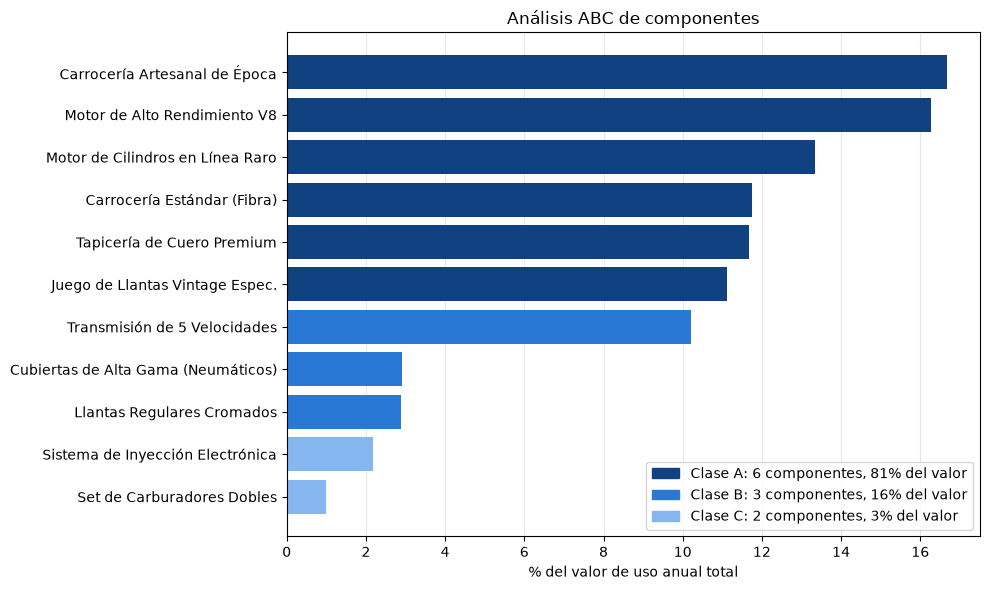

In [6]:
colores = {"A": "#104281", "B": "#2a78d6", "C": "#86b6ef"}

grafico = abc.sort_values("valor de uso anual")
posiciones = list(range(len(grafico)))
colores_barras = [colores[clase] for clase in grafico["clase ABC"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(posiciones, grafico["% del valor"], color=colores_barras)
ax.set_yticks(posiciones)
ax.set_yticklabels(grafico["componente"])

leyenda = []
for clase in ["A", "B", "C"]:
    parte = abc[abc["clase ABC"] == clase]
    texto = f"Clase {clase}: {len(parte)} componentes, {parte['% del valor'].sum():.0f}% del valor"
    leyenda.append(Patch(color=colores[clase], label=texto))
ax.legend(handles=leyenda, loc="lower right")

ax.set_title("Análisis ABC de componentes")
ax.set_xlabel("% del valor de uso anual total")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_SALIDA, "abc_componentes.png"), dpi=150)
plt.show()

## 4. XYZ de los componentes

El XYZ clasifica por variabilidad de la demanda, con el coeficiente de variación: CV = desvío estándar / media × 100. Se calcula con la serie mensual del 01 (29 meses), usando la línea que usa cada componente.

El uso por auto multiplica la media y el desvío por el mismo número, así que no cambia el CV: todos los componentes de una misma línea tienen el mismo.

**Cortes:**

- **X:** CV menor a 20%. **Respaldo de la cátedra:** el apunte usa el 20% como límite para tratar la demanda como determinística (44/73).
- **Y:** CV entre 20% y 50%.
- **Z:** CV mayor a 50%.

El corte de 50% entre Y y Z es **criterio propio**.

In [7]:
cv_lineas = {
    "Clásico": serie["Clasicos"].std() / serie["Clasicos"].mean() * 100,
    "Vintage": serie["Vintage"].std() / serie["Vintage"].mean() * 100,
    "Ambos": serie["Total"].std() / serie["Total"].mean() * 100,
}
for linea in cv_lineas:
    print("CV de la demanda mensual,", linea + ":", round(cv_lineas[linea], 1), "%")

abc["CV %"] = abc["auto"].map(cv_lineas)

clases_xyz = []
for cv in abc["CV %"]:
    if cv < 20:
        clases_xyz.append("X")
    elif cv <= 50:
        clases_xyz.append("Y")
    else:
        clases_xyz.append("Z")
abc["clase XYZ"] = clases_xyz

abc[["componente", "auto", "CV %", "clase ABC", "clase XYZ"]].round(1)

CV de la demanda mensual, Clásico: 75.0 %
CV de la demanda mensual, Vintage: 69.6 %
CV de la demanda mensual, Ambos: 71.7 %


,componente,auto,CV %,clase ABC,clase XYZ
2,Carrocería Artesanal de Época,Vintage,69.6,A,Z
0,Motor de Alto Rendimiento V8,Clásico,75.0,A,Z
1,Motor de Cilindros en Línea Raro,Vintage,69.6,A,Z
3,Carrocería Estándar (Fibra),Clásico,75.0,A,Z
7,Tapicería de Cuero Premium,Ambos,71.7,A,Z
8,Juego de Llantas Vintage Espec.,Vintage,69.6,A,Z
4,Transmisión de 5 Velocidades,Ambos,71.7,B,Z
10,Cubiertas de Alta Gama (Neumáticos),Ambos,71.7,B,Z
9,Llantas Regulares Cromados,Clásico,75.0,B,Z
5,Sistema de Inyección Electrónica,Clásico,75.0,C,Z


**Resultado:** los 11 componentes son clase Z, con un CV de 70% a 75%. La demanda es muy variable, y eso justifica usar modelos probabilísticos con stock de seguridad, como pide la consigna.

**Ojo:** este CV incluye el pico de noviembre, que el pronóstico sí anticipa. Por eso sirve para clasificar, pero el stock de seguridad no se calcula con él, sino con el error de pronóstico, que es la parte que el modelo no puede anticipar (sección 6).

### Chequeo con el método del apunte

El apunte propone otro uso del CV para caracterizar la demanda (44/73). Lo llama **V**: es el mismo coeficiente de variación que el CV del XYZ (desvío estándar / media × 100). Lo que cambia son los datos: V se calcula para cada mes del año, comparando ese mes entre los distintos años (enero de 2003, de 2004 y de 2005, por ejemplo). Con eso distingue cuatro casos:

1. El promedio de cada mes es parecido y V es chico (menor a 20%): **determinística y constante**.
2. El promedio cambia entre meses, pero V es chico en todos: **determinística pero variable**.
3. El promedio es parecido y V es alto (mayor a 20%) pero parecido en todos los meses: **probabilística y estacionaria**.
4. El promedio y V cambian mucho de un mes a otro: **probabilística no estacionaria**.

La celda calcula, para cada mes del año, cuántos años tienen dato, el promedio del total y el V de cada serie.

In [8]:
mes_del_anio = pd.PeriodIndex(serie.index, freq="M").month

por_mes = pd.DataFrame({
    "años con dato": serie["Total"].groupby(mes_del_anio).count(),
    "promedio Total": serie["Total"].groupby(mes_del_anio).mean(),
    "V Total %": serie["Total"].groupby(mes_del_anio).std() / serie["Total"].groupby(mes_del_anio).mean() * 100,
    "V Clásicos %": serie["Clasicos"].groupby(mes_del_anio).std() / serie["Clasicos"].groupby(mes_del_anio).mean() * 100,
    "V Vintage %": serie["Vintage"].groupby(mes_del_anio).std() / serie["Vintage"].groupby(mes_del_anio).mean() * 100,
})
por_mes.index.name = "mes"
por_mes.round(0)

,años con dato,promedio Total,V Total %,V Clásicos %,V Vintage %
mes,,,,,
1,3,1643.0,39.0,57.0,19.0
2,3,1326.0,65.0,76.0,58.0
3,3,1453.0,13.0,18.0,14.0
4,3,1211.0,36.0,37.0,43.0
5,3,1563.0,51.0,46.0,61.0
6,2,680.0,6.0,5.0,16.0
7,2,1402.0,34.0,35.0,34.0
8,2,1668.0,90.0,98.0,74.0
9,2,1659.0,6.0,25.0,21.0


**Resultado:** el promedio va de unos 700 autos (junio) a unos 6.000 (noviembre), y V va de casi 0% a 98% según el mes. Es el caso 4: **demanda probabilística no estacionaria**. Coincide con el XYZ: todos los componentes son Z.

**Limitación:** cada mes del año tiene solo 2 o 3 años de datos.

## 5. Resultado: componentes para los modelos de inventario

Los modelos de inventario (políticas A y B, capacidad de almacén y sensibilidad) se aplican solo a los componentes clase A. **Respaldo de la cátedra:** la consigna dice que el ABC y el XYZ sirven para "identificar los Componentes sobre los cuales recaerá la aplicación de los modelos avanzados de inventario" (sección 2).

Se guarda la tabla completa de los 11 componentes en `outputs/componentes.csv`, con nombres de columna sin espacios ni tildes. Los pasos siguientes la leen de ahí.

In [9]:
salida = abc[["componente", "auto", "costo unitario", "uso por auto", "volumen m3", "lead time semanas",
              "demanda anual", "valor de uso anual", "% del valor", "% acumulado", "clase ABC",
              "CV %", "clase XYZ"]].copy()
salida = salida.rename(columns={
    "costo unitario": "costo_unitario",
    "uso por auto": "uso_por_auto",
    "volumen m3": "volumen_m3",
    "lead time semanas": "lead_time_semanas",
    "demanda anual": "demanda_anual",
    "valor de uso anual": "valor_uso_anual",
    "% del valor": "porcentaje_valor",
    "% acumulado": "porcentaje_acumulado",
    "clase ABC": "clase_abc",
    "CV %": "cv_porcentaje",
    "clase XYZ": "clase_xyz",
})
salida.round(2).to_csv(os.path.join(CARPETA_SALIDA, "componentes.csv"), index=False)
print("Guardado en", CARPETA_SALIDA)

clase_a = salida[salida["clase_abc"] == "A"]
print("\nComponentes clase A:", len(clase_a), "| clases:", ", ".join(sorted(set(clase_a["clase_abc"] + clase_a["clase_xyz"]))))
for nombre in clase_a["componente"]:
    print(" -", nombre)

Guardado en outputs

Componentes clase A: 6 | clases: AZ
 - Carrocería Artesanal de Época
 - Motor de Alto Rendimiento V8
 - Motor de Cilindros en Línea Raro
 - Carrocería Estándar (Fibra)
 - Tapicería de Cuero Premium
 - Juego de Llantas Vintage Espec.


## 6. Parámetros de riesgo

Para los 6 componentes clase A se calculan los datos que necesitan las dos políticas de inventario. La rúbrica pide, para cada componente, el **costo de agotamiento** y la **desviación estándar** ("Parámetros de Riesgo").

Todo va **por año**, porque la consigna da el costo de mantener por año: la demanda D es anual, y c1 también.

### 6.1 Costo de pedido y costo de mantener

Los dos salen de la consigna ("Contexto del Caso"):

- **K** = $300 por pedido.
- **c1** = 20% del costo unitario del componente, por año.

La celda arma la tabla `parametros` con los componentes clase A y les agrega c1.

In [10]:
K = 300

parametros = abc[abc["clase ABC"] == "A"].copy()
parametros["c1"] = 0.2 * parametros["costo unitario"]
parametros[["componente", "auto", "costo unitario", "c1"]]

,componente,auto,costo unitario,c1
2,Carrocería Artesanal de Época,Vintage,15000,3000.0
0,Motor de Alto Rendimiento V8,Clásico,9000,1800.0
1,Motor de Cilindros en Línea Raro,Vintage,12000,2400.0
3,Carrocería Estándar (Fibra),Clásico,6500,1300.0
7,Tapicería de Cuero Premium,Ambos,4000,800.0
8,Juego de Llantas Vintage Espec.,Vintage,2500,500.0


### 6.2 Costo de agotamiento (c2)

La consigna fija una compensación al cliente: un descuento del 5% sobre el precio del auto por la demora.

El precio de un auto es `SALES / QUANTITYORDERED × 1000`, como indicó la cátedra. Para cada línea se usa el precio promedio: la suma de `SALES` dividida por la suma de autos, por 1000, sin los pedidos cancelados (mismo criterio que el 01). Como control, la cantidad de autos tiene que coincidir con la del 01: 33.499 Clásicos y 20.609 Vintage.

Dos decisiones de **criterio propio**:

- **Componentes de las dos líneas** (la tapicería): se usa el precio promedio de las dos líneas juntas, porque un faltante demora un auto de cualquiera de las dos, en la proporción en que se venden.
- **Componentes con 4 unidades por auto** (las llantas vintage): el descuento es por auto, y cada auto lleva 4 llantas. Por eso el costo por llanta faltante es el 5% del precio dividido por 4.

In [11]:
RUTA_DATOS = "data/sales_data_sample_raw.csv"

ventas = pd.read_csv(RUTA_DATOS, encoding="latin-1")
ventas = ventas[ventas["STATUS"] != "Cancelled"]

clasicos = ventas[ventas["PRODUCTLINE"] == "Classic Cars"]
vintage = ventas[ventas["PRODUCTLINE"] == "Vintage Cars"]
ambas = ventas[ventas["PRODUCTLINE"].isin(["Classic Cars", "Vintage Cars"])]

print("Autos: Clásicos", clasicos["QUANTITYORDERED"].sum(), "| Vintage", vintage["QUANTITYORDERED"].sum())

precio_auto = {
    "Clásico": clasicos["SALES"].sum() / clasicos["QUANTITYORDERED"].sum() * 1000,
    "Vintage": vintage["SALES"].sum() / vintage["QUANTITYORDERED"].sum() * 1000,
    "Ambos": ambas["SALES"].sum() / ambas["QUANTITYORDERED"].sum() * 1000,
}
for linea in precio_auto:
    print("Precio promedio de un auto,", linea + ": $", round(precio_auto[linea]))

parametros["precio del auto"] = parametros["auto"].map(precio_auto)
parametros["c2"] = 0.05 * parametros["precio del auto"] / parametros["uso por auto"]
parametros[["componente", "auto", "precio del auto", "uso por auto", "c2"]].round(0)

Autos: Clásicos 33499 | Vintage 20609
Precio promedio de un auto, Clásico: $ 115238
Precio promedio de un auto, Vintage: $ 90499
Precio promedio de un auto, Ambos: $ 105815


,componente,auto,precio del auto,uso por auto,c2
2,Carrocería Artesanal de Época,Vintage,90499.0,1,4525.0
0,Motor de Alto Rendimiento V8,Clásico,115238.0,1,5762.0
1,Motor de Cilindros en Línea Raro,Vintage,90499.0,1,4525.0
3,Carrocería Estándar (Fibra),Clásico,115238.0,1,5762.0
7,Tapicería de Cuero Premium,Ambos,105815.0,1,5291.0
8,Juego de Llantas Vintage Espec.,Vintage,90499.0,4,1131.0


### 6.3 Desviación estándar del error de pronóstico

El 02 guarda el desvío mensual del error de pronóstico de cada línea (sección 7 del 02): el RMSE de la diferencia entre la venta real de la línea y su parte del pronóstico. **Respaldo de la cátedra:** el RMSE estima la desviación estándar del error de pronóstico (presentación *Modelos de Pronósticos*, diapositiva 15).

El desvío de cada componente es el de su línea multiplicado por el uso por auto: si se venden 100 autos vintage más de lo pronosticado, faltan 400 llantas. Los componentes de las dos líneas usan el desvío del total.

In [12]:
desvio_linea = {
    "Clásico": demanda["desvio_error_mensual_clasicos"],
    "Vintage": demanda["desvio_error_mensual_vintage"],
    "Ambos": demanda["desvio_error_mensual_total"],
}

parametros["σ mensual"] = parametros["auto"].map(desvio_linea) * parametros["uso por auto"]
parametros[["componente", "auto", "uso por auto", "σ mensual"]].round(1)

,componente,auto,uso por auto,σ mensual
2,Carrocería Artesanal de Época,Vintage,1,151.9
0,Motor de Alto Rendimiento V8,Clásico,1,320.3
1,Motor de Cilindros en Línea Raro,Vintage,1,151.9
3,Carrocería Estándar (Fibra),Clásico,1,320.3
7,Tapicería de Cuero Premium,Ambos,1,401.1
8,Juego de Llantas Vintage Espec.,Vintage,4,607.6


### 6.4 Demanda durante el lead time

La variable x de los modelos es la demanda durante el lead time. Como en el apunte (65/73), se supone normal, con:

- $E[x] = d \cdot L$
- $\sigma_x = \sigma \cdot \sqrt{L}$

donde d es la demanda mensual (D / 12), σ el desvío mensual y L el lead time en meses.

El lead time de la consigna está en semanas. Se pasa a meses con L = semanas × 12 / 52, porque un año tiene 52 semanas. Es **criterio propio**: el apunte redondea a 4 semanas por mes (1 semana = 0,25 mes, 66/73).

Ejemplo: el motor V8 tiene un lead time de 6 semanas, que son 1,38 meses. Su demanda mensual es 20.204,5 / 12 = 1.684 motores, así que E[x] = 1.684 × 1,38 ≈ 2.331 motores.

In [13]:
parametros["L meses"] = parametros["lead time semanas"] * 12 / 52
parametros["E[x]"] = parametros["demanda anual"] / 12 * parametros["L meses"]
parametros["σx"] = parametros["σ mensual"] * parametros["L meses"] ** 0.5
parametros[["componente", "lead time semanas", "L meses", "E[x]", "σx"]].round(2)

,componente,lead time semanas,L meses,E[x],σx
2,Carrocería Artesanal de Época,10,2.31,2390.38,230.75
0,Motor de Alto Rendimiento V8,6,1.38,2331.29,376.90
1,Motor de Cilindros en Línea Raro,12,2.77,2868.46,252.78
3,Carrocería Estándar (Fibra),4,0.92,1554.19,307.73
7,Tapicería de Cuero Premium,8,1.85,5020.69,544.99
8,Juego de Llantas Vintage Espec.,5,1.15,4780.77,652.67


### 6.5 Chequeo: ¿tiene solución la política A?

La política A usa el algoritmo de Hadley-Whitin, que converge cuando $\tilde{q} \geq \hat{q}$ (apunte, 52/73):

- $\hat{q} = \sqrt{2D\,(K + c_2 \, E[x]) / c_1}$
- $\tilde{q} = c_2 \, D / c_1$

La celda verifica la condición para cada componente.

In [14]:
parametros["q sombrero"] = (2 * parametros["demanda anual"] * (K + parametros["c2"] * parametros["E[x]"]) / parametros["c1"]) ** 0.5
parametros["q tilde"] = parametros["c2"] * parametros["demanda anual"] / parametros["c1"]
parametros["¿cumple?"] = parametros["q tilde"] >= parametros["q sombrero"]
parametros[["componente", "q sombrero", "q tilde", "¿cumple?"]].round(0)

,componente,q sombrero,q tilde,¿cumple?
2,Carrocería Artesanal de Época,9468.0,18748.0,True
0,Motor de Alto Rendimiento V8,17366.0,64676.0,True
1,Motor de Cilindros en Línea Raro,11595.0,23435.0,True
3,Carrocería Estándar (Fibra),16684.0,89551.0,True
7,Tapicería de Cuero Premium,46553.0,215827.0,True
8,Juego de Llantas Vintage Espec.,32797.0,112490.0,True


**Resultado:** los seis componentes cumplen la condición, así que la política A va a tener solución para todos.

### 6.6 Resultado: tabla de parámetros

Se guarda en `outputs/parametros.csv`, con nombres de columna sin espacios ni tildes; el notebook 04 la lee de ahí. La tabla que muestra la celda es la que va al informe.

In [15]:
guardar = parametros[["componente", "auto", "costo unitario", "uso por auto", "volumen m3", "lead time semanas",
                      "demanda anual", "c1", "precio del auto", "c2", "σ mensual", "L meses", "E[x]", "σx"]].copy()
guardar = guardar.rename(columns={
    "costo unitario": "costo_unitario",
    "uso por auto": "uso_por_auto",
    "volumen m3": "volumen_m3",
    "lead time semanas": "lead_time_semanas",
    "demanda anual": "demanda_anual",
    "precio del auto": "precio_auto",
    "σ mensual": "desvio_mensual",
    "L meses": "lead_time_meses",
    "E[x]": "media_x",
    "σx": "desvio_x",
})
guardar.insert(2, "K", K)
guardar.round(4).to_csv(os.path.join(CARPETA_SALIDA, "parametros.csv"), index=False)
print("Guardado en", CARPETA_SALIDA)

parametros[["componente", "demanda anual", "c1", "c2", "σ mensual", "E[x]", "σx"]].round(0)

Guardado en outputs


,componente,demanda anual,c1,c2,σ mensual,E[x],σx
2,Carrocería Artesanal de Época,12430.0,3000.0,4525.0,152.0,2390.0,231.0
0,Motor de Alto Rendimiento V8,20204.0,1800.0,5762.0,320.0,2331.0,377.0
1,Motor de Cilindros en Línea Raro,12430.0,2400.0,4525.0,152.0,2868.0,253.0
3,Carrocería Estándar (Fibra),20204.0,1300.0,5762.0,320.0,1554.0,308.0
7,Tapicería de Cuero Premium,32634.0,800.0,5291.0,401.0,5021.0,545.0
8,Juego de Llantas Vintage Espec.,49720.0,500.0,1131.0,608.0,4781.0,653.0


## 7. Limitaciones, para el informe

- **Transmisión al límite:** queda en B por poco (10,2% del valor, contra 11,1% de las llantas vintage).
- **Reparto fijo:** las demandas por línea salen de proporciones históricas fijas (61,9% Clásicos y 38,1% Vintage). Si la mezcla cambia, cambia el valor de cada componente. El total pronosticado, en cambio, no afecta las clases: si sube o baja, todos los valores cambian en la misma proporción.
- **Cortes del ABC:** el 80% y el 95% son convenciones (Miranda, *Sistemas de optimización de stocks*). Con un corte de 75% para la clase A, el resultado es el mismo (sección 3).
- **CV con estacionalidad:** el CV del XYZ incluye el pico de noviembre. Clasifica la variabilidad de la demanda, pero no es la incertidumbre que usa el stock de seguridad, que sale del error de pronóstico (sección 6).
- **Demanda normal:** se supone que la demanda durante el lead time es normal, como en el apunte (65/73). Con 29 meses no se puede comprobar.
- **Meses independientes:** σx = σ · √L supone que el error de un mes no depende del error de otro mes.
- **Conversión de semanas:** con 4 semanas por mes, como redondea el apunte (66/73), los lead times en meses serían un 8% más largos, y E[x] un 8% más alto.
- **c2 por criterio propio:** el precio promedio para la tapicería y la división por 4 para las llantas vintage. Si una sola llanta faltante ya demorara el auto, el c2 de las llantas sería 4 veces mayor.